# 00 · Quantum basics: one useful experiment

**Goal:** see how a circuit changes the chance of measuring `0` or `1`.

Run: [setup](../SETUP.md). Qiskit ideal simulation; saved outputs are local. Run your version in qBraid Lab (or implement it in Classiq).

## What you need to know

- A **qubit** has a quantum state; measuring it gives one classical bit. We start in state `0`.
- **Amplitudes** are weights for possible outcomes. Their squared magnitudes give probabilities. Unlike probabilities, amplitudes can have signs (more generally, complex phases).
- A **gate** changes the state. `H` creates equal amplitudes from `0`; a second `H` undoes the first. `Z` flips the sign of the `1` amplitude without changing its probability.
- **Interference** combines amplitudes so they reinforce or cancel. Quantum algorithms use this to make useful answers more likely.
- A **shot** is one preparation, circuit run, and measurement. It gives one outcome, not all possible answers.

**Predict:** compare `H → H` with `H → Z → H`. Does changing a sign between the H gates change the measured answer?

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

SHOTS, SEED = 512, 7
print(f"Qiskit {qiskit.__version__} | ideal Statevector | {SHOTS} shots | seed {SEED}")

# Qubits start at 0. Apply gates in the order written.
equal = QuantumCircuit(1)
equal.h(0)

undo = equal.copy()
undo.h(0)

change_sign = equal.copy()
change_sign.z(0)
change_sign.h(0)

circuits = {"H": equal, "H → H": undo, "H → Z → H": change_sign}

Qiskit 2.3.0 | ideal Statevector | 512 shots | seed 7


## Run and check

`Statevector` simulates an ideal circuit on an ordinary computer. It exposes exact probabilities for learning; `sample_counts` draws simulated measurements from them. A physical device supplies samples and also introduces errors.

Read the circuit **left to right**: the top wire is the qubit; the meter reads it into the bottom classical wire. The dashed barrier only separates stages.

H: measured 1 in 271 of 512 shots
H → H: measured 1 in 0 of 512 shots
H → Z → H: measured 1 in 512 of 512 shots


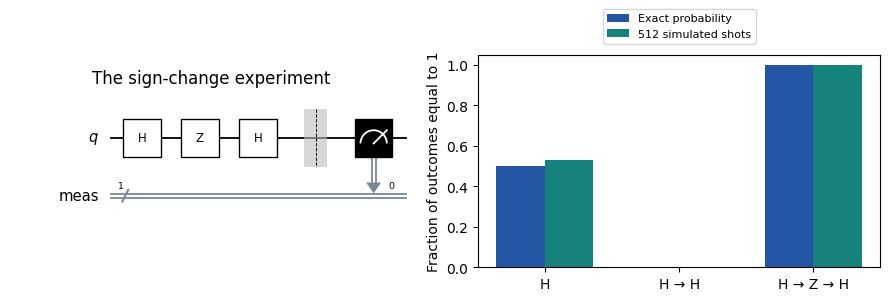

In [2]:
exact, observed = [], []
for label, circuit in circuits.items():
    state = Statevector.from_instruction(circuit)
    state.seed(SEED)
    counts = state.sample_counts(SHOTS)
    exact.append(state.probabilities()[1])
    observed.append(counts.get("1", 0) / SHOTS)
    print(f"{label}: measured 1 in {counts.get('1', 0)} of {SHOTS} shots")

# Classical arithmetic: H maps (a,b) to ((a+b)/sqrt(2), (a-b)/sqrt(2)).
# Equal signs cancel the 1 outcome; opposite signs cancel the 0 outcome.
np.testing.assert_allclose(exact, [0.5, 0, 1], atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
drawing = change_sign.copy()
drawing.measure_all()
drawing.draw("mpl", ax=axes[0], style="bw", fold=-1)
axes[0].set_title("The sign-change experiment")
x = np.arange(len(circuits))
axes[1].bar(x - 0.18, exact, 0.36, label="Exact probability", color="#2456a6")
axes[1].bar(x + 0.18, observed, 0.36, label=f"{SHOTS} simulated shots", color="#16827c")
axes[1].set(xticks=x, xticklabels=list(circuits), ylabel="Fraction of outcomes equal to 1",
            ylim=(0, 1.05))
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.24))
plt.tight_layout()
plt.show()

**Result:** a phase change becomes a different answer through interference. A 50/50 random bit alone cannot explain the whole experiment. These circuits are easy to simulate; this is not a speedup demonstration.

**Try:** add another `change_sign.z(0)` immediately before its final H. Predict, rerun, and update the expected answer in the check.

Next: choose [Deutsch–Jozsa](01_deutsch_jozsa.ipynb), [Bernstein–Vazirani](02_bernstein_vazirani.ipynb), [Grover](03_grover_search.ipynb), or [QAOA](04_qaoa_maxcut.ipynb).

Reference: [IBM's explanation of qubit states and gates](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/quantum-information).